### Der getriebene harmonische Oszillator

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

## Modell

Die DGL des gedämpften harmonischen Oszillators ist durch 

$m\ddot{x}(t) = -2m\gamma\dot{x}(t) + kx(t) + F_0 \sin(\omega t)$ 

gegeben. Die Implementierung dieser DGL 2. Ordnung erfolgt durch zwei gekoppelte DGLs 1. Ordnung:

$\dot{x} = \frac{p}{m}$

$\dot{p} = -2\gamma p - m\omega_0^2 x + F_0\sin(\omega t)$,

wobei $p$ tatsächlich der Impuls ist und $\omega_0^2 = k/m$.

In [2]:
# Declare the model for the inhomogeneous equation
def inhom_model(t, y, omega, gamma, m, F_0, omega_d, phase):
    x, p = y
    dx = p / m
    dp =  - 2 * gamma * p - m * omega**2 * x + F_0*np.sin(omega_d*t + phase)
    return (dx, dp)

In [3]:
def amp_func(m, omega, gamma, F_0, omega_d):
    return F_0/(m*np.sqrt((omega**2 - omega_d**2)**2 + 4*gamma**2*omega**2))

def phase_func(omega, gamma, omega_d):
    return np.arctan2(2*gamma*omega_d, omega**2 - omega_d**2)

def particular_sol(t, m, omega, gamma, F_0, omega_d, phase):

    amp = amp_func(m, omega, gamma, F_0, omega_d)
    phase = phase_func(omega, gamma, omega_d)
    return amp*np.sin(omega_d*t - phase)

### Schwaches Treiben mit halber System Frequenz $\omega = 0.5\omega_0$

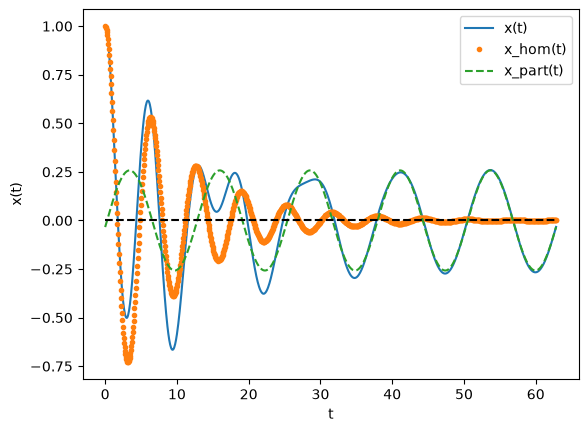

In [4]:
omega = 1.0
gamma = 0.1
m = 1.0

F_0 = 0.2
omega_d = 0.5
phase = 0.0

T = 20 * np.pi

t = np.linspace(0.0, T, 1000)
x_init = np.array([1.0, 0.])

# standard ode-solver
x_ho = odeint(inhom_model, x_init, t, args=(omega, gamma, m, 0, omega_d, phase), tfirst=True)
x = odeint(inhom_model, x_init, t, args=(omega, gamma, m, F_0, omega_d, phase), tfirst=True)

plt.plot(t, x[:, 0], label="x(t)")  # y[:,0} is the first column of y
plt.plot(t, x_ho[:, 0], '.', label="x_hom(t)")  # y[:,0} is the first column of y
plt.plot(t, particular_sol(t, m, omega, gamma, F_0, omega_d, phase), '--', label="x_part(t)")  # y[:,0} is the first column of y
plt.plot(t, np.zeros(len(t)), '--', color="black")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="upper right")
plt.show()

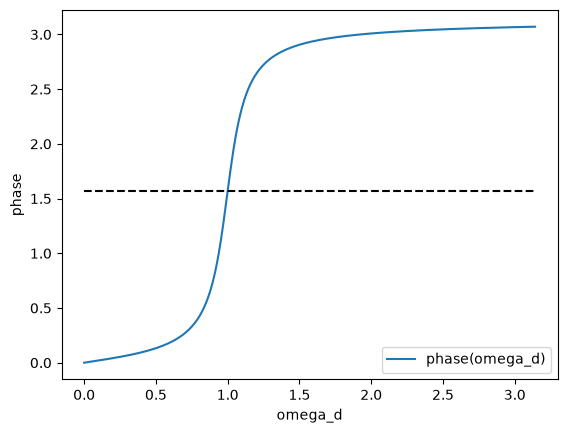

In [5]:
omega_d = np.linspace(0, np.pi, 500)
plt.plot(omega_d, phase_func(omega, gamma, omega_d), label="phase(omega_d)")  # y[:,0} is the first column of y
plt.plot(omega_d, np.pi/2*np.ones(len(omega_d)), '--', color='black')  # y[:,0} is the first column of y
plt.xlabel("omega_d")
plt.ylabel("phase")
plt.legend(loc="lower right")
plt.show()

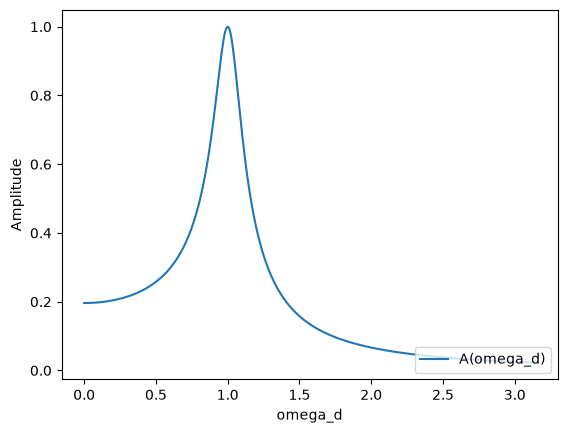

In [6]:
plt.plot(omega_d, amp_func(m, omega, gamma, F_0, omega_d), label="A(omega_d)")  # y[:,0} is the first column of y
plt.xlabel("omega_d")
plt.ylabel("Amplitude")
plt.legend(loc="lower right")
plt.show()


### Resonanz $\gamma\neq 0$, $\omega = \omega_0$ 

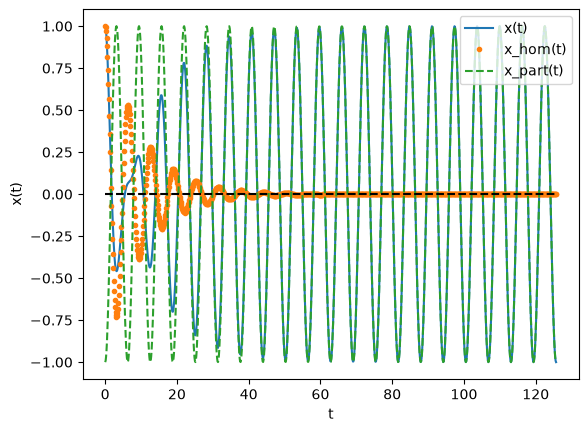

In [7]:
omega = 1.0
gamma = 0.1
m = 1.0

F_0 = 0.2
omega_d = omega
phase = 0.0

T = 40 * np.pi

t = np.linspace(0.0, T, 1000)
x_init = np.array([1.0, 0.])

# standard ode-solver
x_ho = odeint(inhom_model, x_init, t, args=(omega, gamma, m, 0, omega_d, phase), tfirst=True)
x = odeint(inhom_model, x_init, t, args=(omega, gamma, m, F_0, omega_d, phase), tfirst=True)

plt.plot(t, x[:, 0], label="x(t)")  # y[:,0} is the first column of y
plt.plot(t, x_ho[:, 0], '.', label="x_hom(t)")  # y[:,0} is the first column of y
plt.plot(t, particular_sol(t, m, omega, gamma, F_0, omega_d, phase), '--', label="x_part(t)")  # y[:,0} is the first column of y
plt.plot(t, np.zeros(len(t)), '--', color="black")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="upper right")
plt.show()


### Resonanzkatastrophe $\gamma=0$, $\omega = \omega_0$ 

In [8]:
def x_resonance(t, m, omega, gamma, F_0):
    return (-F_0/m)*t*np.cos(omega*t)/(2*omega)

def x_resonance_eveloping(t, m, omega, gamma, F_0):
    return (-F_0/m)*t/(2*omega)

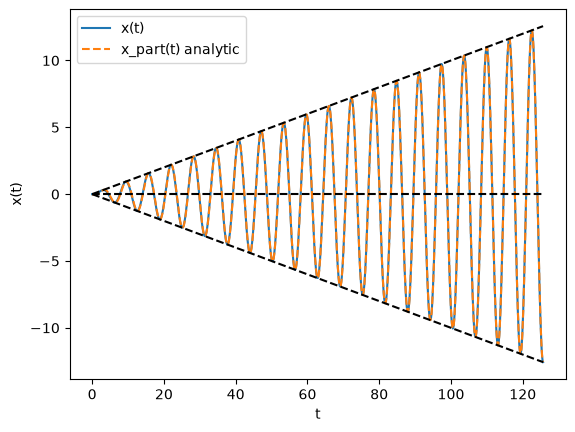

In [9]:
omega = 1.0
gamma = 0.0
m = 1.0

F_0 = 0.2
omega_d = omega
phase = 0.0

T = 40 * np.pi

t = np.linspace(0.0, T, 1000)
x_init = np.array([0., 0.])

# standard ode-solver
x_ho = odeint(inhom_model, x_init, t, args=(omega, gamma, m, 0, omega_d, phase), tfirst=True)
x = odeint(inhom_model, x_init, t, args=(omega, gamma, m, F_0, omega_d, phase), tfirst=True)

plt.plot(t, x[:, 0], label="x(t)")  # y[:,0} is the first column of y
# plt.plot(t, x_ho[:, 0], '.', label="x_hom(t)")  # y[:,0} is the first column of y
plt.plot(t, x_resonance(t, m, omega_d, gamma, F_0), '--', label="x_part(t) analytic")  # y[:,0} is the first column of y
plt.plot(t, -x_resonance_eveloping(t, m, omega_d, gamma, F_0), '--', color='black')  # y[:,0} is the first column of y
plt.plot(t, x_resonance_eveloping(t, m, omega_d, gamma, F_0), '--', color='black')  # y[:,0} is the first column of y
plt.plot(t, np.zeros(len(t)), '--', color="black")
plt.xlabel("t")
plt.ylabel("x(t)")
plt.legend(loc="upper left")
plt.show()